# EfficientDet – Object Localization & Classification (20 Dog Breeds)
## ver2 – Refactored Pipeline

In [12]:
# Cell 3 ─ Fix DLL loading & import torch
# MUST run this cell FIRST after kernel restart, BEFORE any other imports
import os, sys, ctypes

# ── Identify torch lib path ────────────────────────────────────────────────
torch_lib = os.path.join(sys.prefix, "Lib", "site-packages", "torch", "lib")
if not os.path.isdir(torch_lib):
    # fallback for non-venv
    torch_lib = r"c:\Users\MY MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\lib"
print(f"Python : {sys.executable}")
print(f"Torch lib: {torch_lib}  (exists={os.path.isdir(torch_lib)})")

# ── Workaround: add DLL dirs + preload VC runtimes ────────────────────────
os.add_dll_directory(torch_lib)
os.environ["PATH"] = torch_lib + ";" + os.environ.get("PATH", "")
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Preload VC runtimes explicitly
for rt in ["vcruntime140.dll", "msvcp140.dll", "vcruntime140_1.dll"]:
    try:
        ctypes.CDLL(rt)
        print(f"  preload {rt}: OK")
    except OSError:
        print(f"  preload {rt}: MISSING")

# Preload c10.dll via ctypes (different loading path than LoadLibraryExW)
try:
    ctypes.CDLL(os.path.join(torch_lib, "c10.dll"))
    print("  preload c10.dll: OK")
except OSError as e:
    print(f"  preload c10.dll: FAIL ({e})")

# ── Now import torch ──────────────────────────────────────────────────────
import torch
print(f"\ntorch {torch.__version__} imported successfully!")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Python : c:\Users\MY MSI\AppData\Local\Programs\Python\Python312\python.exe
Torch lib: c:\Users\MY MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\lib  (exists=True)
  preload vcruntime140.dll: OK
  preload msvcp140.dll: OK
  preload vcruntime140_1.dll: OK
  preload c10.dll: OK

torch 2.10.0+cu126 imported successfully!
CUDA available: True
GPU: NVIDIA GeForce RTX 2050


In [13]:
# Cell 3 ─ ALL Imports & Config
import os, sys, random, math, copy
from pathlib import Path
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as tvm
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, f1_score, precision_score, recall_score


# ── Paths ─────────────────────────────────────────────────────────────────────
ROOT     = Path("data")
IMG_DIR  = ROOT / "img_resized"    # 512x512 letterboxed (from EDA)
ANNO_DIR = ROOT / "anno_resized"

# ── Hyper-parameters ──────────────────────────────────────────────────────────
IMG_SIZE    = 512
SPLIT       = (0.8, 0.1, 0.1)
BATCH_SIZE  = 16
NUM_WORKERS = 4
SEED        = 42
NUM_EPOCHS  = 15
LR          = 1e-4
LR_BACKBONE = 1e-5
LAMBDA_BBOX = 5.0          # ↑ from 1.5 → push harder on localisation
LAMBDA_L1   = 1.0          # auxiliary Smooth-L1 weight

# ImageNet stats (EfficientNet pretrained)
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# ── Reproducibility ───────────────────────────────────────────────────────────
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Torch       : {torch.__version__}")
print(f"TorchVision : {torchvision.__version__}")
print(f"Device      : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU         : {torch.cuda.get_device_name(0)}")
    print(f"VRAM        : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Torch       : 2.10.0+cu126
TorchVision : 0.25.0+cu126
Device      : cuda
GPU         : NVIDIA GeForce RTX 2050
VRAM        : 4.3 GB


## Step 2 · Scan anno XML → DataFrame

In [14]:
IMG_EXTS = {".jpg", ".jpeg", ".png"}

def parse_anno(anno_path: Path):
    """Parse 1 anno XML -> dict. Union of all bboxes, normalised to [0,1]."""
    try:
        root = ET.parse(anno_path).getroot()
    except ET.ParseError:
        return None

    W = int(root.find("size/width").text)
    H = int(root.find("size/height").text)
    name_el = root.find(".//object/name")
    if name_el is None:
        return None
    class_name = name_el.text.strip()

    xmins, ymins, xmaxs, ymaxs = [], [], [], []
    for bb in root.iter("bndbox"):
        xmins.append(int(bb.find("xmin").text))
        ymins.append(int(bb.find("ymin").text))
        xmaxs.append(int(bb.find("xmax").text))
        ymaxs.append(int(bb.find("ymax").text))
    if not xmins:
        return None

    xmin = max(0, min(xmins));  ymin = max(0, min(ymins))
    xmax = min(W, max(xmaxs));  ymax = min(H, max(ymaxs))

    return {
        "anno_path"  : str(anno_path),
        "class_name" : class_name,
        "img_w": W, "img_h": H,
        "xmin_n": xmin / W, "ymin_n": ymin / H,
        "xmax_n": xmax / W, "ymax_n": ymax / H,
    }

# Collect & parse
anno_paths = [
    p for cls_dir in ANNO_DIR.iterdir() if cls_dir.is_dir()
    for p in cls_dir.iterdir() if p.is_file()
]
with ThreadPoolExecutor() as pool:
    records = [r for r in pool.map(parse_anno, anno_paths) if r is not None]
df = pd.DataFrame(records)

# Resolve image paths
def find_img(anno_path_str):
    ap = Path(anno_path_str)
    img_dir = IMG_DIR / ap.parent.name
    for ext in IMG_EXTS:
        c = img_dir / (ap.stem + ext)
        if c.exists():
            return str(c)
    return None

df["img_path"] = df["anno_path"].map(find_img)
df = df.dropna(subset=["img_path"]).reset_index(drop=True)

# Class mapping
class_names = sorted(df["class_name"].unique().tolist())
NUM_CLASSES = len(class_names)
cls2idx     = {c: i for i, c in enumerate(class_names)}
df["class_idx"] = df["class_name"].map(cls2idx)

print(f"Total samples : {len(df)}")
print(f"Num classes   : {NUM_CLASSES}\n")
for i, c in enumerate(class_names):
    print(f"  {i:2d}  {c:<40s}  {(df['class_name']==c).sum():>4d} samples")

Total samples : 3537
Num classes   : 20

   0  Afghan_hound                               239 samples
   1  African_hunting_dog                        169 samples
   2  Bedlington_terrier                         182 samples
   3  Chihuahua                                  152 samples
   4  French_bulldog                             159 samples
   5  German_short-haired_pointer                152 samples
   6  Irish_wolfhound                            218 samples
   7  Mexican_hairless                           155 samples
   8  Pomeranian                                 219 samples
   9  Rottweiler                                 152 samples
  10  Saint_Bernard                              170 samples
  11  Siberian_husky                             192 samples
  12  basset                                     175 samples
  13  bloodhound                                 187 samples
  14  borzoi                                     151 samples
  15  chow                                  

## Step 3 · Stratified 8:1:1 Split

In [15]:
train_rows, val_rows, test_rows = [], [], []
for cls in class_names:
    idx = df[df["class_name"] == cls].index.tolist()
    random.shuffle(idx)
    n      = len(idx)
    n_val  = max(1, round(n * SPLIT[1]))
    n_test = max(1, round(n * SPLIT[2]))
    n_train = n - n_val - n_test
    train_rows.extend(idx[:n_train])
    val_rows  .extend(idx[n_train : n_train + n_val])
    test_rows .extend(idx[n_train + n_val :])

df_train = df.loc[train_rows].reset_index(drop=True)
df_val   = df.loc[val_rows  ].reset_index(drop=True)
df_test  = df.loc[test_rows ].reset_index(drop=True)

print(f"Train : {len(df_train):>5d}")
print(f"Val   : {len(df_val):>5d}")
print(f"Test  : {len(df_test):>5d}")
assert set(df_train["img_path"]).isdisjoint(set(df_val["img_path"])),  "Train/Val overlap!"
assert set(df_train["img_path"]).isdisjoint(set(df_test["img_path"])), "Train/Test overlap!"
print("No overlap between splits. \u2713")

Train :  2827
Val   :   355
Test  :   355
No overlap between splits. ✓


## Step 4 · Dataset & Transforms

In [16]:
train_transform = T.Compose([
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    T.RandomGrayscale(p=0.05),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

class DogDataset(Dataset):
    """
    Returns (image[3,H,W], bbox[4] normalised, label int).
    cache_in_ram=True → load all images once into memory (~1.5 GB).
    """
    def __init__(self, df, transform=None, augment_hflip=False, cache_in_ram=True):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.augment_hflip = augment_hflip
        self.cache = {}
        if cache_in_ram:
            print(f"  Caching {len(self.df)} images into RAM...", end=" ", flush=True)
            for i in tqdm(range(len(self.df)), desc="Cache", leave=False):
                self.cache[i] = Image.open(self.df.iloc[i]["img_path"]).convert("RGB")
            print("done.")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        # Read from cache or disk
        if i in self.cache:
            img = self.cache[i].copy()  # copy so transforms don't mutate cache
        else:
            img = Image.open(row["img_path"]).convert("RGB")
        bbox = torch.tensor(
            [row["xmin_n"], row["ymin_n"], row["xmax_n"], row["ymax_n"]],
            dtype=torch.float32,
        )
        label = int(row["class_idx"])
        if self.augment_hflip and random.random() < 0.5:
            img = TF.hflip(img)
            bbox[0], bbox[2] = 1.0 - bbox[2], 1.0 - bbox[0]
        if self.transform:
            img = self.transform(img)
        return img, bbox, label


train_ds = DogDataset(df_train, transform=train_transform, augment_hflip=True)
val_ds   = DogDataset(df_val,   transform=eval_transform)
test_ds  = DogDataset(df_test,  transform=eval_transform)

print(f"\nDogDataset ready: train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")
img_t, bbox_t, lbl = train_ds[0]
print(f"  shape={img_t.shape}  bbox={bbox_t}  label={lbl} ({class_names[lbl]})")

  Caching 2827 images into RAM... 

Cache:   0%|          | 0/2827 [00:00<?, ?it/s]

done.
  Caching 355 images into RAM... 

Cache:   0%|          | 0/355 [00:00<?, ?it/s]

done.
  Caching 355 images into RAM... 

Cache:   0%|          | 0/355 [00:00<?, ?it/s]

done.

DogDataset ready: train=2827  val=355  test=355
  shape=torch.Size([3, 512, 512])  bbox=tensor([0.2109, 0.1758, 0.8047, 0.8848])  label=0 (Afghan_hound)


## Step 5 · DataLoader + Class Weights

In [17]:
import time

# Per-class inverse-frequency weights
class_counts = np.bincount(df_train["class_idx"].values, minlength=NUM_CLASSES).astype(np.float32)
class_weights = torch.tensor(
    len(df_train) / (NUM_CLASSES * class_counts), dtype=torch.float32
)
print("Class weights:")
for i, (c, w) in enumerate(zip(class_names, class_weights)):
    print(f"  {i:2d}  {c:<40s}  n={int(class_counts[i]):>4d}  w={w:.4f}")

# WeightedRandomSampler
t0 = time.perf_counter()
sample_weights = class_weights[df_train["class_idx"].values].tolist()
sampler = WeightedRandomSampler(sample_weights, num_samples=len(train_ds), replacement=True)
print(f"\n✓ Sampler ready ({time.perf_counter()-t0:.3f}s)")

# num_workers=0 because data is cached in RAM → no disk I/O, workers would just copy cache & deadlock
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, sampler=sampler,
    num_workers=0, pin_memory=True, drop_last=True,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)
print(f"✓ DataLoaders created  (train={len(train_loader)}  val={len(val_loader)}  test={len(test_loader)})")

# Batch shape check
imgs = torch.stack([train_ds[i][0] for i in range(BATCH_SIZE)])
bboxes = torch.stack([train_ds[i][1] for i in range(BATCH_SIZE)])
labels = torch.tensor([train_ds[i][2] for i in range(BATCH_SIZE)])
print(f"✓ Batch check -> img:{imgs.shape}  bbox:{bboxes.shape}  lbl:{labels.shape}")
del imgs, bboxes, labels

Class weights:
   0  Afghan_hound                              n= 191  w=0.7401
   1  African_hunting_dog                       n= 135  w=1.0470
   2  Bedlington_terrier                        n= 146  w=0.9682
   3  Chihuahua                                 n= 122  w=1.1586
   4  French_bulldog                            n= 127  w=1.1130
   5  German_short-haired_pointer               n= 122  w=1.1586
   6  Irish_wolfhound                           n= 174  w=0.8124
   7  Mexican_hairless                          n= 123  w=1.1492
   8  Pomeranian                                n= 175  w=0.8077
   9  Rottweiler                                n= 122  w=1.1586
  10  Saint_Bernard                             n= 136  w=1.0393
  11  Siberian_husky                            n= 154  w=0.9179
  12  basset                                    n= 139  w=1.0169
  13  bloodhound                                n= 149  w=0.9487
  14  borzoi                                    n= 121  w=1.1682
  15  chow

## Step 6 · Model – EfficientDet-D0

In [18]:
class BiFPNBlock(nn.Module):
    """Single BiFPN layer for 3 feature levels."""
    def __init__(self, ch):
        super().__init__()
        self.w_td = nn.Parameter(torch.ones(2, 3))
        self.w_bu = nn.Parameter(torch.ones(3, 3))
        self.relu = nn.ReLU()
        self.eps  = 1e-4
        _conv = lambda: nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(ch), nn.SiLU(),
        )
        self.conv_td = nn.ModuleList([_conv() for _ in range(2)])
        self.conv_bu = nn.ModuleList([_conv() for _ in range(3)])

    def _fuse(self, w, feats):
        w = self.relu(w) + self.eps
        w = w / w.sum()
        return sum(w[i] * feats[i] for i in range(len(feats)))

    def forward(self, p3, p4, p5):
        # Top-down
        p5_up  = F.interpolate(p5, size=p4.shape[-2:], mode="nearest")
        p4_td  = self.conv_td[0](self._fuse(self.w_td[:, 0], [p4, p5_up]))
        p4_up  = F.interpolate(p4_td, size=p3.shape[-2:], mode="nearest")
        p3_out = self.conv_td[1](self._fuse(self.w_td[:, 1], [p3, p4_up]))
        # Bottom-up
        p3_dn  = F.max_pool2d(p3_out, 2)
        p4_out = self.conv_bu[0](self._fuse(self.w_bu[:, 0], [p4, p4_td, p3_dn]))
        p4_dn  = F.max_pool2d(p4_out, 2)
        p5_out = self.conv_bu[1](self._fuse(self.w_bu[:, 1], [p5, p4_dn]))
        return p3_out, p4_out, p5_out


class EfficientDetD0(nn.Module):
    """
    Backbone : EfficientNet-B0 (pretrained)
    Neck     : BiFPN x3, 64 channels
    Cls Head : GAP → MLP (global features are fine for classification)
    BBox Head: Spatial conv on p3 + GAP context from p5/p7 → MLP → (cx,cy,w,h)
               ↑ Preserves WHERE the object is, not just WHAT
    """
    BIFPN_CH  = 64
    BIFPN_REP = 3

    def __init__(self, num_classes):
        super().__init__()
        bb = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.DEFAULT).features
        self.stage3 = bb[:4]     # 40ch,  stride 8
        self.stage5 = bb[4:6]    # 112ch, stride 16
        self.stage7 = bb[6:9]    # 1280ch, stride 32

        C = self.BIFPN_CH
        self.lat3 = nn.Conv2d(40,   C, 1, bias=False)
        self.lat5 = nn.Conv2d(112,  C, 1, bias=False)
        self.lat7 = nn.Conv2d(1280, C, 1, bias=False)

        self.bifpn = nn.ModuleList([BiFPNBlock(C) for _ in range(self.BIFPN_REP)])
        self.gap   = nn.AdaptiveAvgPool2d(1)

        # ── Classification head (GAP-based, global features) ──────────
        cls_feat_dim = C * 3   # GAP(p3) + GAP(p5) + GAP(p7) = 192
        self.cls_head = nn.Sequential(
            nn.Linear(cls_feat_dim, 256), nn.SiLU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

        # ── BBox head (spatial conv + context) ────────────────────────
        # p3 is C×64×64 (for 512 input). Reduce to C×4×4 via strided conv.
        self.bbox_spatial = nn.Sequential(
            nn.Conv2d(C, C, 3, stride=2, padding=1, bias=False),  # →32
            nn.BatchNorm2d(C), nn.SiLU(),
            nn.Conv2d(C, C, 3, stride=2, padding=1, bias=False),  # →16
            nn.BatchNorm2d(C), nn.SiLU(),
            nn.Conv2d(C, C, 3, stride=2, padding=1, bias=False),  # →8
            nn.BatchNorm2d(C), nn.SiLU(),
            nn.Conv2d(C, C, 3, stride=2, padding=1, bias=False),  # →4
            nn.BatchNorm2d(C), nn.SiLU(),
        )
        # spatial(C×4×4)=1024  +  GAP(p5)=C  +  GAP(p7)=C  =  1152
        bbox_feat_dim = C * 4 * 4 + C * 2
        self.bbox_head = nn.Sequential(
            nn.Linear(bbox_feat_dim, 256), nn.SiLU(), nn.Dropout(0.2),
            nn.Linear(256, 4),
        )

    def forward(self, x):
        # ─ Backbone ──────────────────────────────────────────────
        c3 = self.stage3(x)
        c5 = self.stage5(c3)
        c7 = self.stage7(c5)
        p3, p5, p7 = self.lat3(c3), self.lat5(c5), self.lat7(c7)

        # ─ BiFPN ─────────────────────────────────────────────────
        for blk in self.bifpn:
            p3, p5, p7 = blk(p3, p5, p7)

        # ─ Cls head (GAP → global features) ──────────────────────
        cls_feat = torch.cat([
            self.gap(p3).flatten(1),
            self.gap(p5).flatten(1),
            self.gap(p7).flatten(1),
        ], dim=1)
        cls_logits = self.cls_head(cls_feat)

        # ─ BBox head (spatial conv on p3 + coarse context) ───────
        sp   = self.bbox_spatial(p3).flatten(1)          # B, C*4*4
        ctx  = torch.cat([
            self.gap(p5).flatten(1),
            self.gap(p7).flatten(1),
        ], dim=1)                                         # B, C*2
        bbox_feat = torch.cat([sp, ctx], dim=1)           # B, 1152

        raw  = self.bbox_head(bbox_feat)                  # B, 4
        cxcy = torch.sigmoid(raw[:, :2])                  # center [0,1]
        wh   = torch.sigmoid(raw[:, 2:])                  # w,h    [0,1]
        x1y1 = (cxcy - wh / 2).clamp(0.0, 1.0)
        x2y2 = (cxcy + wh / 2).clamp(0.0, 1.0)
        bbox  = torch.cat([x1y1, x2y2], dim=1)           # B, 4

        return cls_logits, bbox


model = EfficientDetD0(NUM_CLASSES).to(DEVICE)
total_p  = sum(p.numel() for p in model.parameters())
train_p  = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Params: {total_p/1e6:.2f}M total, {train_p/1e6:.2f}M trainable")

with torch.no_grad():
    dummy = torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    co, bo = model(dummy)
print(f"Smoke test -> cls:{co.shape}  bbox:{bo.shape}")
print(f"Init bbox sample: {bo[0].cpu().tolist()}")

Params: 5.15M total, 5.15M trainable
Smoke test -> cls:torch.Size([2, 20])  bbox:torch.Size([2, 4])
Init bbox sample: [0.2934904098510742, 0.2567097246646881, 0.7743932008743286, 0.7407015562057495]


## Step 7 · Loss Functions

In [19]:
cls_criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))


def ciou_loss(pred, target):
    """Complete-IoU loss for normalised boxes (N,4) [x1,y1,x2,y2].
    CIoU = IoU  −  ρ²(center)/c²  −  α·v
    where v penalises aspect-ratio mismatch, converging faster than GIoU.
    """
    px1, py1, px2, py2 = pred.unbind(1)
    tx1, ty1, tx2, ty2 = target.unbind(1)

    # Intersection
    ix1 = torch.max(px1, tx1); iy1 = torch.max(py1, ty1)
    ix2 = torch.min(px2, tx2); iy2 = torch.min(py2, ty2)
    inter = (ix2 - ix1).clamp(0) * (iy2 - iy1).clamp(0)

    # Areas
    pw = (px2 - px1).clamp(min=1e-6); ph = (py2 - py1).clamp(min=1e-6)
    tw = (tx2 - tx1).clamp(min=1e-6); th = (ty2 - ty1).clamp(min=1e-6)
    pa = pw * ph;  ta = tw * th
    union = pa + ta - inter + 1e-7
    iou   = inter / union

    # Enclosing box diagonal²
    ex1 = torch.min(px1, tx1); ey1 = torch.min(py1, ty1)
    ex2 = torch.max(px2, tx2); ey2 = torch.max(py2, ty2)
    c2 = (ex2 - ex1) ** 2 + (ey2 - ey1) ** 2 + 1e-7

    # Center distance²
    pcx = (px1 + px2) / 2;  pcy = (py1 + py2) / 2
    tcx = (tx1 + tx2) / 2;  tcy = (ty1 + ty2) / 2
    rho2 = (pcx - tcx) ** 2 + (pcy - tcy) ** 2

    # Aspect-ratio penalty
    v = (4 / (math.pi ** 2)) * (
        torch.atan(tw / th) - torch.atan(pw / ph)
    ) ** 2
    with torch.no_grad():
        alpha = v / (1 - iou + v + 1e-7)

    ciou = iou - rho2 / c2 - alpha * v
    return (1.0 - ciou).mean()


def total_loss(cls_logits, bbox_pred, labels, bbox_gt):
    lc     = cls_criterion(cls_logits, labels)
    lb_ciou = ciou_loss(bbox_pred, bbox_gt)
    lb_l1   = F.smooth_l1_loss(bbox_pred, bbox_gt)
    lb      = lb_ciou + LAMBDA_L1 * lb_l1          # combined bbox loss
    return lc + LAMBDA_BBOX * lb, lc.item(), lb.item()


print(f"Loss = CE(weighted) + {LAMBDA_BBOX} × (CIoU + {LAMBDA_L1} × SmoothL1)")

Loss = CE(weighted) + 5.0 × (CIoU + 1.0 × SmoothL1)


## Step 8 · Optimiser & Scheduler

In [20]:
backbone_ids = set(
    id(p) for m in [model.stage3, model.stage5, model.stage7,
                    model.lat3, model.lat5, model.lat7]
    for p in m.parameters()
)
bbox_ids = set(
    id(p) for m in [model.bbox_spatial, model.bbox_head]
    for p in m.parameters()
)
backbone_params = [p for p in model.parameters() if id(p) in backbone_ids]
bbox_params     = [p for p in model.parameters() if id(p) in bbox_ids]
other_params    = [p for p in model.parameters()
                   if id(p) not in backbone_ids and id(p) not in bbox_ids]

LR_BBOX = LR * 2  # higher LR for bbox regression head

optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": other_params,    "lr": LR},
    {"params": bbox_params,     "lr": LR_BBOX},
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr          = [LR_BACKBONE * 10, LR * 10, LR_BBOX * 10],
    steps_per_epoch = len(train_loader),
    epochs          = NUM_EPOCHS,
    pct_start       = 0.1,
)

scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

n_bb  = sum(p.numel() for p in backbone_params)
n_box = sum(p.numel() for p in bbox_params)
n_oth = sum(p.numel() for p in other_params)
print(f"AdamW  backbone:{n_bb/1e6:.2f}M@{LR_BACKBONE}  other:{n_oth/1e6:.2f}M@{LR}  bbox:{n_box/1e6:.2f}M@{LR_BBOX}")
print(f"OneCycleLR {NUM_EPOCHS} epochs | AMP={'ON' if DEVICE.type=='cuda' else 'OFF'}")

AdamW  backbone:4.10M@1e-05  other:0.61M@0.0001  bbox:0.44M@0.0002
OneCycleLR 15 epochs | AMP=ON


## Step 9 · Training Loop

In [21]:
history = {k: [] for k in [
    "train_loss", "train_cls", "train_bbox",
    "val_loss",   "val_cls",   "val_bbox",
    "val_acc",    "val_iou",
]}
best_val_loss = float("inf")
best_weights  = None


def iou_batch(pred, target):
    ix1 = torch.max(pred[:,0], target[:,0])
    iy1 = torch.max(pred[:,1], target[:,1])
    ix2 = torch.min(pred[:,2], target[:,2])
    iy2 = torch.min(pred[:,3], target[:,3])
    inter = (ix2-ix1).clamp(0) * (iy2-iy1).clamp(0)
    pa = (pred[:,2]-pred[:,0]).clamp(0) * (pred[:,3]-pred[:,1]).clamp(0)
    ta = (target[:,2]-target[:,0]).clamp(0) * (target[:,3]-target[:,1]).clamp(0)
    return (inter / (pa + ta - inter + 1e-7)).mean().item()


def run_epoch_train(loader):
    model.train()
    tot = tot_c = tot_b = 0.0
    pbar = tqdm(loader, desc="  Train", leave=False)
    for imgs, bboxes, labels in pbar:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        bboxes = bboxes.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            cls_out, bbox_out = model(imgs)
            loss, lc, lb = total_loss(cls_out, bbox_out, labels, bboxes)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        # Only step scheduler when optimizer actually updated (no inf grads)
        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= old_scale:
            scheduler.step()

        tot += loss.item(); tot_c += lc; tot_b += lb
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    n = len(loader)
    return tot/n, tot_c/n, tot_b/n


@torch.no_grad()
def run_epoch_val(loader):
    model.eval()
    tot = tot_c = tot_b = 0.0
    correct = total_n = 0
    iou_sum = 0.0
    pbar = tqdm(loader, desc="  Val  ", leave=False)
    for imgs, bboxes, labels in pbar:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        bboxes = bboxes.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            cls_out, bbox_out = model(imgs)
            loss, lc, lb = total_loss(cls_out, bbox_out, labels, bboxes)

        tot += loss.item(); tot_c += lc; tot_b += lb
        correct += (cls_out.argmax(1) == labels).sum().item()
        total_n += labels.size(0)
        iou_sum += iou_batch(bbox_out, bboxes)
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    n = len(loader)
    return tot/n, tot_c/n, tot_b/n, correct/total_n, iou_sum/n


# ── Free VRAM before training ──────────────────────────────────────────────
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

epoch_bar = tqdm(range(1, NUM_EPOCHS + 1), desc="Epochs", unit="ep")
for epoch in epoch_bar:
    tl, tcl, tbl         = run_epoch_train(train_loader)
    vl, vcl, vbl, va, vi = run_epoch_val(val_loader)

    history["train_loss"].append(tl);  history["train_cls"].append(tcl)
    history["train_bbox"].append(tbl)
    history["val_loss"].append(vl);    history["val_cls"].append(vcl)
    history["val_bbox"].append(vbl)
    history["val_acc"].append(va);     history["val_iou"].append(vi)

    marker = ""
    if vl < best_val_loss:
        best_val_loss = vl
        best_weights = copy.deepcopy(model.state_dict())
        marker = " *"

    epoch_bar.set_postfix(
        T=f"{tl:.3f}", V=f"{vl:.3f}",
        Acc=f"{va*100:.1f}%", IoU=f"{vi:.4f}"
    )
    tqdm.write(
        f"Epoch {epoch:3d}/{NUM_EPOCHS} | "
        f"T {tl:.4f} (c={tcl:.4f} b={tbl:.4f}) | "
        f"V {vl:.4f} (c={vcl:.4f} b={vbl:.4f}) | "
        f"Acc {va*100:.1f}%  IoU {vi:.4f}" + marker
    )

model.load_state_dict(best_weights)
print(f"\nDone. Best val loss: {best_val_loss:.4f}")

Epochs:   0%|          | 0/15 [00:00<?, ?ep/s]

  Train:   0%|          | 0/176 [00:00<?, ?it/s]

  Val  :   0%|          | 0/23 [00:00<?, ?it/s]

Epoch   1/15 | T 4.9745 (c=2.8903 b=0.4168) | V 4.7035 (c=2.7181 b=0.3971) | Acc 14.9%  IoU 0.6205 *


  Train:   0%|          | 0/176 [00:00<?, ?it/s]

  Val  :   0%|          | 0/23 [00:00<?, ?it/s]

... (36 outputs left out)

Epoch  14/15 | T 0.7268 (c=0.0829 b=0.1288) | V 0.6916 (c=0.0592 b=0.1265) | Acc 98.3%  IoU 0.8759 *


  Train:   0%|          | 0/176 [00:00<?, ?it/s]

  Val  :   0%|          | 0/23 [00:00<?, ?it/s]

Epoch  15/15 | T 0.7110 (c=0.0842 b=0.1254) | V 0.6955 (c=0.0677 b=0.1255) | Acc 97.7%  IoU 0.8767

Done. Best val loss: 0.6916


## Step 10 · Loss Curves

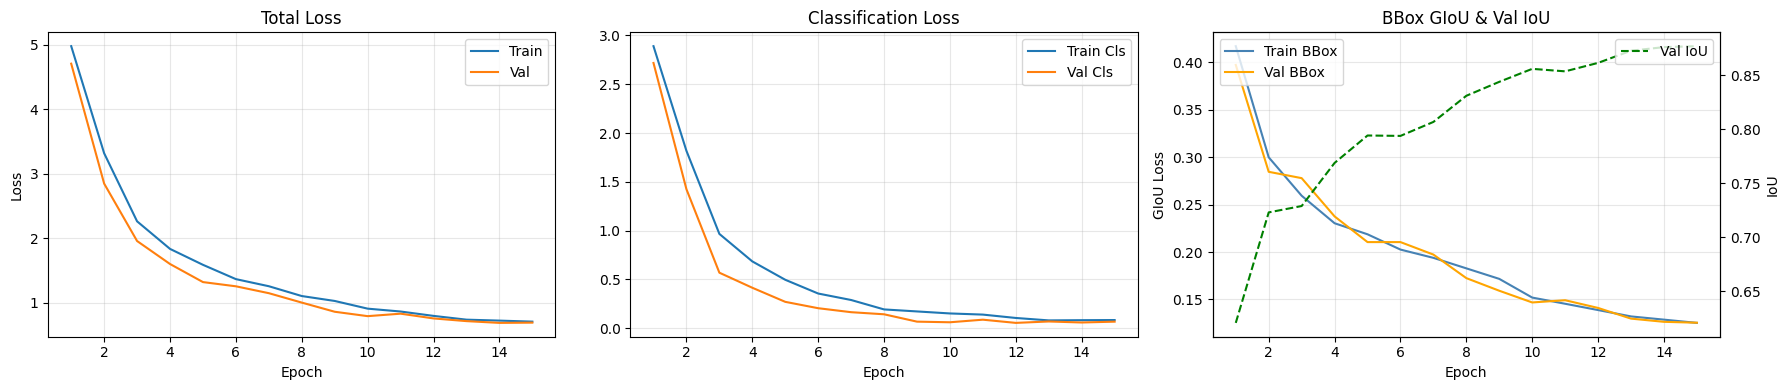

Best Val Acc : 98.59% (epoch 12)
Best Val IoU : 0.8767  (epoch 15)


In [22]:
ep = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(ep, history["train_loss"], label="Train")
axes[0].plot(ep, history["val_loss"],   label="Val")
axes[0].set(title="Total Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ep, history["train_cls"], label="Train Cls")
axes[1].plot(ep, history["val_cls"],   label="Val Cls")
axes[1].set(title="Classification Loss", xlabel="Epoch")
axes[1].legend(); axes[1].grid(alpha=0.3)

ax2 = axes[2]
ax2.plot(ep, history["train_bbox"], label="Train BBox", color="steelblue")
ax2.plot(ep, history["val_bbox"],   label="Val BBox",   color="orange")
ax2.set(title="BBox GIoU & Val IoU", xlabel="Epoch", ylabel="GIoU Loss")
ax2.legend(loc="upper left"); ax2.grid(alpha=0.3)
ax3 = ax2.twinx()
ax3.plot(ep, history["val_iou"], label="Val IoU", color="green", ls="--")
ax3.set_ylabel("IoU"); ax3.legend(loc="upper right")

plt.tight_layout(); plt.show()

best_acc_ep = np.argmax(history["val_acc"]) + 1
best_iou_ep = np.argmax(history["val_iou"]) + 1
print(f"Best Val Acc : {max(history['val_acc'])*100:.2f}% (epoch {best_acc_ep})")
print(f"Best Val IoU : {max(history['val_iou']):.4f}  (epoch {best_iou_ep})")

## Step 11 · Test Evaluation

In [23]:

model.eval()
all_labels, all_preds, all_bp, all_bg = [], [], [], []

with torch.no_grad():
    for imgs, bboxes, labels in tqdm(test_loader, desc="Test"):
        imgs   = imgs.to(DEVICE, non_blocking=True)
        bboxes = bboxes.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            co, bo = model(imgs)
        all_labels.append(labels.cpu())
        all_preds .append(co.argmax(1).cpu())
        all_bp.append(bo.cpu())
        all_bg.append(bboxes.cpu())

all_labels = torch.cat(all_labels).numpy()
all_preds  = torch.cat(all_preds).numpy()
all_bp     = torch.cat(all_bp)
all_bg     = torch.cat(all_bg)

# Vectorised IoU
def iou_vec(p, g):
    i1 = torch.max(p[:,0], g[:,0]); j1 = torch.max(p[:,1], g[:,1])
    i2 = torch.min(p[:,2], g[:,2]); j2 = torch.min(p[:,3], g[:,3])
    inter = (i2-i1).clamp(0) * (j2-j1).clamp(0)
    pa = (p[:,2]-p[:,0]).clamp(0)*(p[:,3]-p[:,1]).clamp(0)
    ga = (g[:,2]-g[:,0]).clamp(0)*(g[:,3]-g[:,1]).clamp(0)
    return inter / (pa + ga - inter + 1e-7)

per_iou = iou_vec(all_bp, all_bg).numpy()
test_acc = (all_labels == all_preds).mean()

# ── Overall metrics ───────────────────────────────────────────────────────
macro_f1  = f1_score(all_labels, all_preds, average="macro")
macro_p   = precision_score(all_labels, all_preds, average="macro", zero_division=0)
macro_r   = recall_score(all_labels, all_preds, average="macro", zero_division=0)
w_f1      = f1_score(all_labels, all_preds, average="weighted")

print("=" * 90)
print(f"  Test Accuracy   : {test_acc*100:.2f}%")
print(f"  Macro Precision : {macro_p*100:.2f}%")
print(f"  Macro Recall    : {macro_r*100:.2f}%")
print(f"  Macro F1        : {macro_f1*100:.2f}%")
print(f"  Weighted F1     : {w_f1*100:.2f}%")
print(f"  Mean IoU        : {per_iou.mean():.4f}")
print("=" * 90)

# ── Per-class table: Precision / Recall / F1 / mIoU / AP@50 ──────────────
IOU_THRESH = 0.5
per_cls_p = precision_score(all_labels, all_preds, average=None, zero_division=0)
per_cls_r = recall_score(all_labels, all_preds, average=None, zero_division=0)
per_cls_f = f1_score(all_labels, all_preds, average=None, zero_division=0)

short = [c.split("-",1)[-1].replace("_"," ") for c in class_names]
header = f"{'Class':<30s} {'#':>4} {'Prec':>6} {'Rec':>6} {'F1':>6} {'mIoU':>6} {'AP50':>6}"
print(header)
print("-" * len(header))

ap_list = []
for i, cn in enumerate(short):
    m = all_labels == i
    if m.sum() == 0:
        continue
    miou = per_iou[m].mean()
    ap   = ((all_preds[m] == i) & (per_iou[m] >= IOU_THRESH)).mean()
    ap_list.append(ap)
    print(f"  {cn:<28s} {m.sum():>4d} {per_cls_p[i]*100:>5.1f}% {per_cls_r[i]*100:>5.1f}% "
          f"{per_cls_f[i]*100:>5.1f}% {miou:>6.4f} {ap:>6.4f}")

mAP50 = np.mean(ap_list)
print("-" * len(header))
print(f"  {'MACRO AVG':<28s} {'':>4} {macro_p*100:>5.1f}% {macro_r*100:>5.1f}% "
      f"{macro_f1*100:>5.1f}% {per_iou.mean():>6.4f} {mAP50:>6.4f}")
print()

# ── sklearn classification_report (full) ──────────────────────────────────
print(classification_report(all_labels, all_preds, target_names=short, digits=3, zero_division=0))

Test:   0%|          | 0/23 [00:00<?, ?it/s]

  Test Accuracy   : 96.62%
  Macro Precision : 96.58%
  Macro Recall    : 96.45%
  Macro F1        : 96.36%
  Weighted F1     : 96.53%
  Mean IoU        : 0.8695
Class                             #   Prec    Rec     F1   mIoU   AP50
----------------------------------------------------------------------
  Afghan hound                   24 100.0%  91.7%  95.7% 0.8800 0.9167
  African hunting dog            17 100.0% 100.0% 100.0% 0.8789 1.0000
  Bedlington terrier             18 100.0%  94.4%  97.1% 0.8923 0.9444
  Chihuahua                      15  90.9%  66.7%  76.9% 0.8270 0.6667
  French bulldog                 16  93.8%  93.8%  93.8% 0.8837 0.9375
  haired pointer                 15 100.0% 100.0% 100.0% 0.8904 1.0000
  Irish wolfhound                22 100.0% 100.0% 100.0% 0.7869 0.9091
  Mexican hairless               16  93.8%  93.8%  93.8% 0.8773 0.9375
  Pomeranian                     22  95.7% 100.0%  97.8% 0.9005 1.0000
  Rottweiler                     15  93.8% 100.0%  96.8% 

## Step 12 · Confusion Matrix

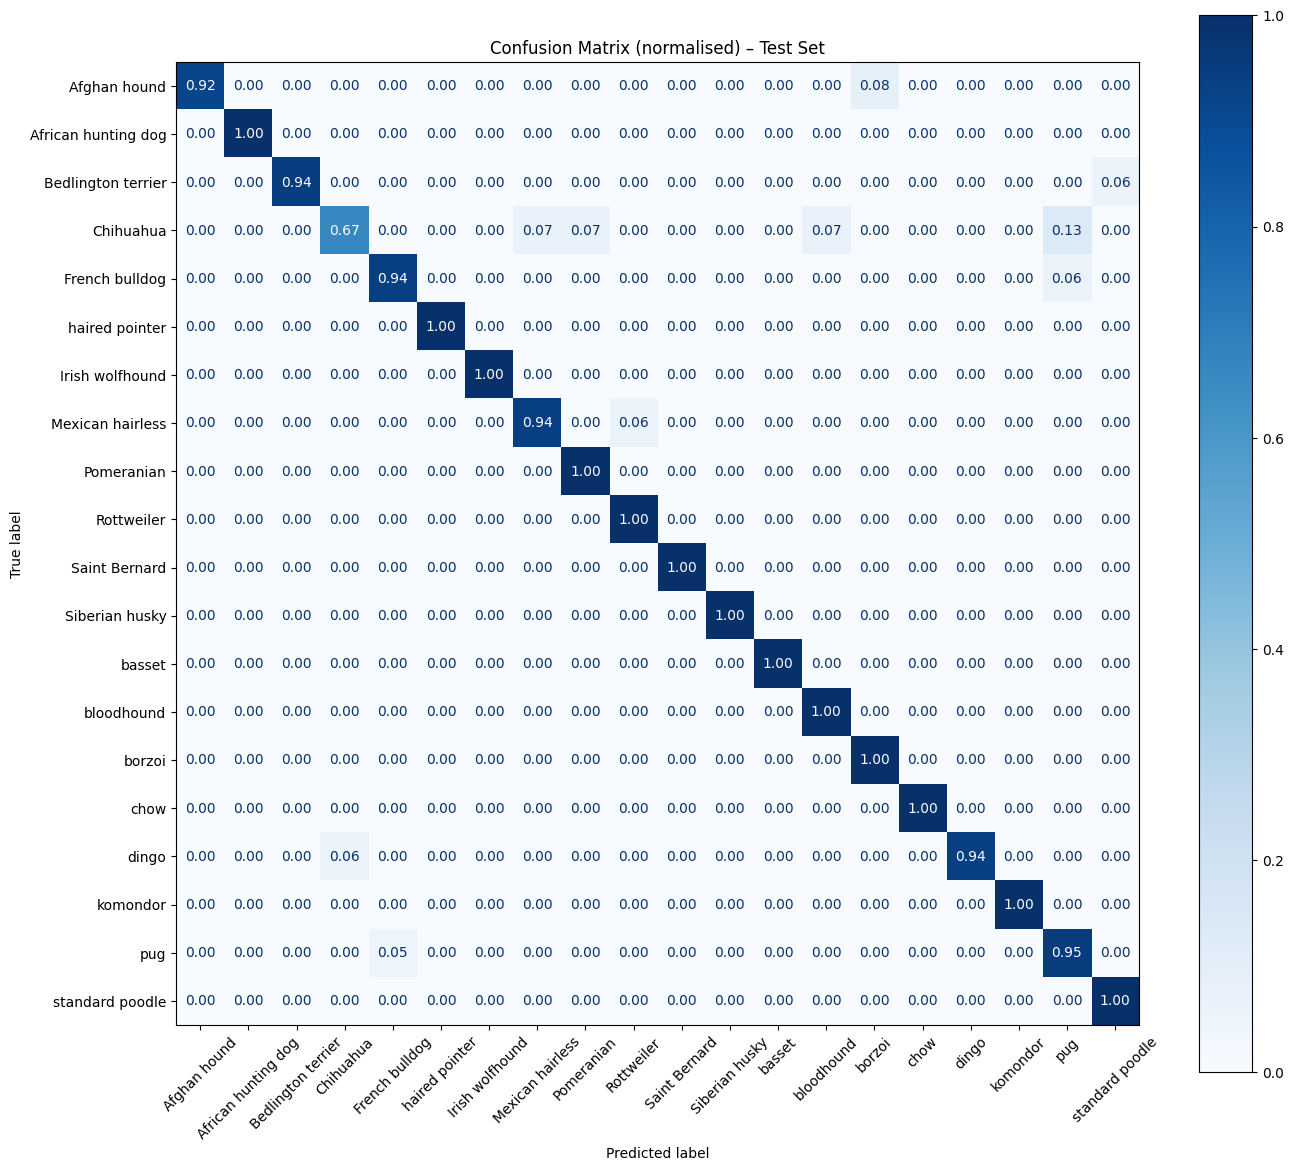

In [24]:
short_names = [c.split("-", 1)[-1].replace("_", " ") for c in class_names]

cm = confusion_matrix(all_labels, all_preds, labels=list(range(NUM_CLASSES)))
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(1)

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(cm_n, display_labels=short_names).plot(
    ax=ax, colorbar=True, cmap="Blues", values_format=".2f", xticks_rotation=45
)
ax.set_title("Confusion Matrix (normalised) \u2013 Test Set")
plt.tight_layout(); plt.show()

## Step 13 · Inference Visualisation

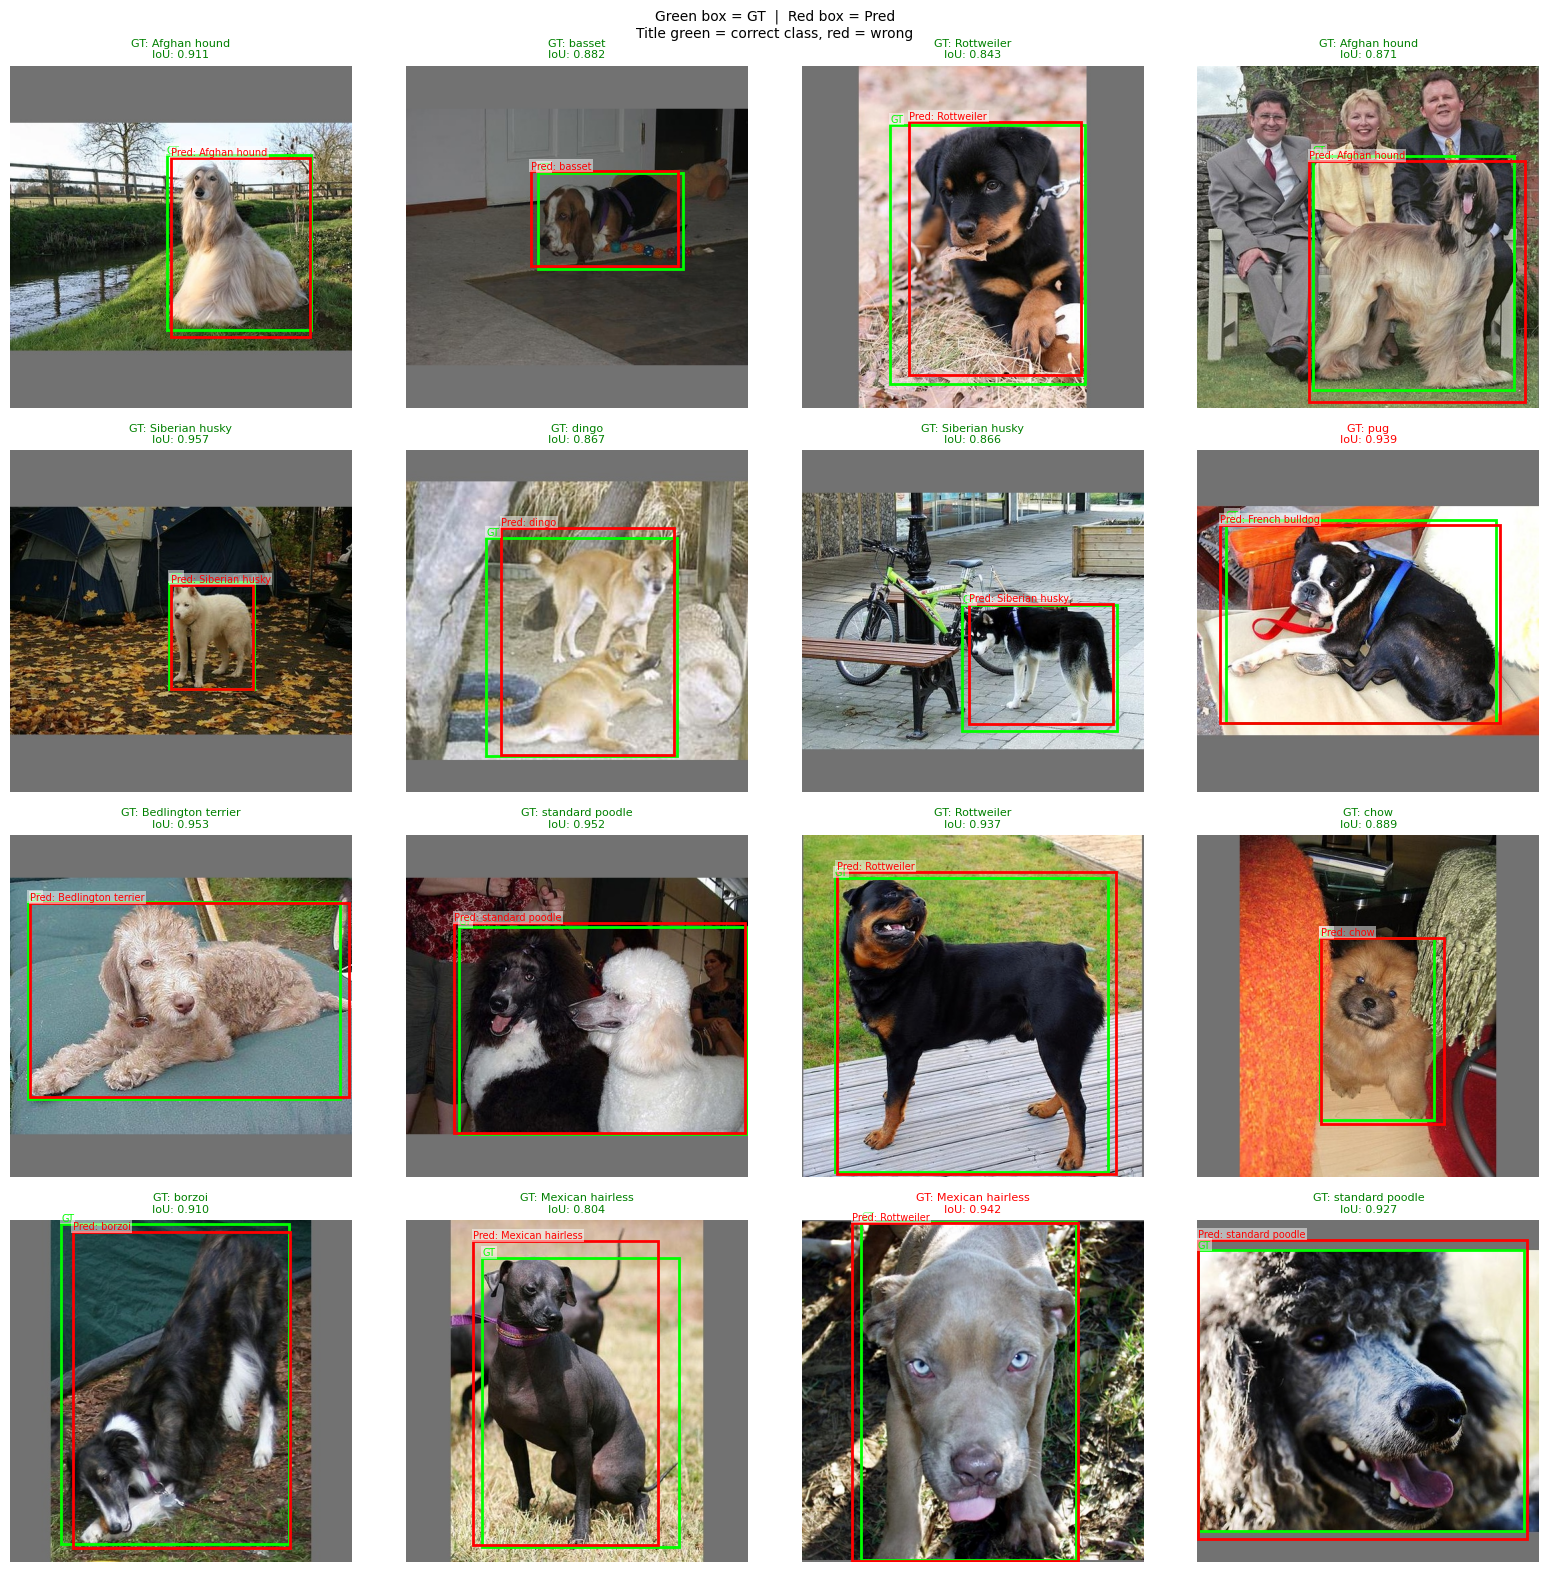

In [25]:
MEAN_T = torch.tensor(MEAN).view(3,1,1)
STD_T  = torch.tensor(STD).view(3,1,1)
denorm = lambda t: (t * STD_T + MEAN_T).clamp(0, 1)

def iou_single(p, g):
    ix1=max(p[0],g[0]); iy1=max(p[1],g[1])
    ix2=min(p[2],g[2]); iy2=min(p[3],g[3])
    inter=max(0,ix2-ix1)*max(0,iy2-iy1)
    pa=max(0,p[2]-p[0])*max(0,p[3]-p[1])
    ga=max(0,g[2]-g[0])*max(0,g[3]-g[1])
    return inter/(pa+ga-inter+1e-7)

def draw_box(ax, bn, color, label, s=IMG_SIZE):
    x1,y1,x2,y2 = bn[0]*s, bn[1]*s, bn[2]*s, bn[3]*s
    ax.add_patch(patches.Rectangle(
        (x1,y1), x2-x1, y2-y1, lw=2, edgecolor=color, facecolor="none"
    ))
    ax.text(x1, y1-4, label, color=color, fontsize=7,
            bbox=dict(facecolor="white", alpha=.5, pad=1, edgecolor="none"))

model.eval()
indices = random.sample(range(len(test_ds)), min(16, len(test_ds)))
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.flatten()

with torch.no_grad():
    for ai, idx in enumerate(indices):
        img_t, bbox_gt, lbl_gt = test_ds[idx]
        inp = img_t.unsqueeze(0).to(DEVICE)
        with torch.amp.autocast("cuda", enabled=(DEVICE.type=="cuda")):
            co, bo = model(inp)
        pred_lbl  = co.argmax(1).item()
        pred_bbox = bo[0].cpu().numpy()
        gt_bbox   = bbox_gt.numpy()
        iv = iou_single(pred_bbox, gt_bbox)

        img_np = (denorm(img_t).permute(1,2,0).numpy()*255).astype(np.uint8)
        ax = axes[ai]
        ax.imshow(img_np)
        draw_box(ax, gt_bbox,   "lime", "GT")
        draw_box(ax, pred_bbox, "red",  f"Pred: {short_names[pred_lbl]}")
        tc = "green" if pred_lbl == lbl_gt else "red"
        ax.set_title(f"GT: {short_names[lbl_gt]}\nIoU: {iv:.3f}", fontsize=8, color=tc)
        ax.axis("off")

plt.suptitle("Green box = GT  |  Red box = Pred\n"
             "Title green = correct class, red = wrong", fontsize=10)
plt.tight_layout(); plt.show()